# Chirp mass vs. redshift for the DINGO training set

A DINGO waveform dataset only stores **intrinsic** parameters. Luminosity distance is an
extrinsic parameter that is drawn from `extrinsic_prior` at train time, so the
waveforms in the file are generated at a fixed reference distance.

To get a redshift for each waveform, this notebook does the following:
1. It reads the parameters of the first `N` waveforms, which gives the detector-frame chirp mass.
2. It draws a luminosity distance per waveform from the same prior used in `train_settings.yaml`.
3. It converts distance to redshift using the prior's own cosmology.
4. It plots detector-frame and source-frame chirp mass, $\mathcal{M}_\mathrm{src} = \mathcal{M}_\mathrm{det}/(1+z)$, against $z$.

It also flags any of these waveforms that contain NaN/inf, which is useful for the NaN-loss debugging.

In [3]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bilby.gw.prior import UniformComovingVolume

WAVEFORM_DATASET = "/scratch/tpausch/waveforms/waveform_dataset_ET_HF_imbh.hdf5"
N = 1000

# Must match extrinsic_prior.luminosity_distance in train_settings.yaml
D_MIN, D_MAX = 500.0, 120_000.0   # Mpc
SEED = 42

## 1. Inspect the file structure

In [4]:
with h5py.File(WAVEFORM_DATASET, "r") as f:
    def show(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"{name:50s} {str(obj.shape):20s} {obj.dtype}")
        else:
            print(f"{name:50s} (group)")
    f.visititems(show)

parameters                                         (5000000,)           [('chirp_mass', '<f8'), ('mass_ratio', '<f8'), ('phase', '<f8'), ('chi_1', '<f8'), ('chi_2', '<f8'), ('theta_jn', '<f8'), ('luminosity_distance', '<f8'), ('geocent_time', '<f8')]
polarizations                                      (group)
polarizations/h_cross                              (5000000, 400)       complex128
polarizations/h_plus                               (5000000, 400)       complex128
svd                                                (group)
svd/V                                              (2049, 400)          complex128
svd/mismatches                                     (20000,)             [('chirp_mass', '<f8'), ('mass_ratio', '<f8'), ('phase', '<f8'), ('chi_1', '<f8'), ('chi_2', '<f8'), ('theta_jn', '<f8'), ('luminosity_distance', '<f8'), ('geocent_time', '<f8'), ('mismatch n=50', '<f8'), ('mismatch n=100', '<f8'), ('mismatch n=150', '<f8'), ('mismatch n=200', '<f8'), ('mismatch n=250', '<f8'

## 2. Read parameters (and check polarizations for NaN/inf)

In [5]:
def read_parameters(f, n):
    p = f["parameters"]
    if isinstance(p, h5py.Dataset):        # DataFrame stored as structured array
        df = pd.DataFrame(p[:n])
    else:                                   # group with one dataset per parameter
        df = pd.DataFrame({k: p[k][:n] for k in p.keys()})
    df.columns = [c.decode() if isinstance(c, bytes) else c for c in df.columns]
    return df

def bad_waveform_mask(f, n):
    """True where any polarization (or SVD coefficient) is NaN/inf."""
    bad = np.zeros(n, dtype=bool)
    if "polarizations" not in f:
        print("No 'polarizations' group found; skipping NaN check.")
        return bad
    for key in f["polarizations"]:
        d = f["polarizations"][key][:n]
        bad |= ~np.isfinite(d).reshape(len(d), -1).all(axis=1)
    return bad

with h5py.File(WAVEFORM_DATASET, "r") as f:
    params = read_parameters(f, N)
    n = len(params)
    bad = bad_waveform_mask(f, n)

print(f"Read {n} waveforms. Columns: {list(params.columns)}")
print(f"Waveforms with NaN/inf: {bad.sum()} / {n}")
if "luminosity_distance" in params:
    print("Stored (reference) luminosity_distance values:",
          np.unique(params["luminosity_distance"])[:5])
params.describe().T

Read 1000 waveforms. Columns: ['chirp_mass', 'mass_ratio', 'phase', 'chi_1', 'chi_2', 'theta_jn', 'luminosity_distance', 'geocent_time']
Waveforms with NaN/inf: 0 / 1000
Stored (reference) luminosity_distance values: [1000.]


,count,mean,std,min,25%,50%,75%,max
chirp_mass,1000.0,817.537826,282.449563,78.892212,622.899546,886.477288,1050.177421,1199.384114
mass_ratio,1000.0,0.404030,0.245176,0.125447,0.199095,0.331457,0.571060,0.999907
phase,1000.0,3.203725,1.833941,0.002626,1.570431,3.249078,4.785139,6.282404
chi_1,1000.0,0.000418,0.293210,-0.842431,-0.164345,0.000130,0.158343,0.815009
chi_2,1000.0,0.016855,0.298453,-0.871364,-0.144155,0.010571,0.179400,0.803418
theta_jn,1000.0,1.545553,0.696892,0.022530,1.014457,1.580213,2.057527,3.061688
luminosity_distance,1000.0,1000.000000,0.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
geocent_time,1000.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [6]:
# Detector-frame chirp mass (compute from component masses if not stored)
if "chirp_mass" not in params:
    m1, m2 = params["mass_1"], params["mass_2"]
    params["chirp_mass"] = (m1 * m2) ** 0.6 / (m1 + m2) ** 0.2
mc_det = params["chirp_mass"].to_numpy()

## 3. Sample distances from the training prior and convert to redshift

In [7]:
prior = UniformComovingVolume(minimum=D_MIN, maximum=D_MAX, name="luminosity_distance")
np.random.seed(SEED)
d_L = np.asarray(prior.sample(n))

# Distance -> redshift via interpolation on the prior's cosmology (fast and vectorised)
z_grid = np.logspace(-4, np.log10(30), 5000)
dL_grid = prior.cosmology.luminosity_distance(z_grid).to("Mpc").value
z = np.interp(d_L, dL_grid, z_grid)

mc_src = mc_det / (1 + z)
print(f"Cosmology: {prior.cosmology.name}")
print(f"z range: {z.min():.3f} - {z.max():.3f}")
print(f"Prior z range: {np.interp(D_MIN, dL_grid, z_grid):.3f} - {np.interp(D_MAX, dL_grid, z_grid):.3f}")

Cosmology: Planck15
z range: 0.335 - 11.141
Prior z range: 0.105 - 11.145


## 4. Plot

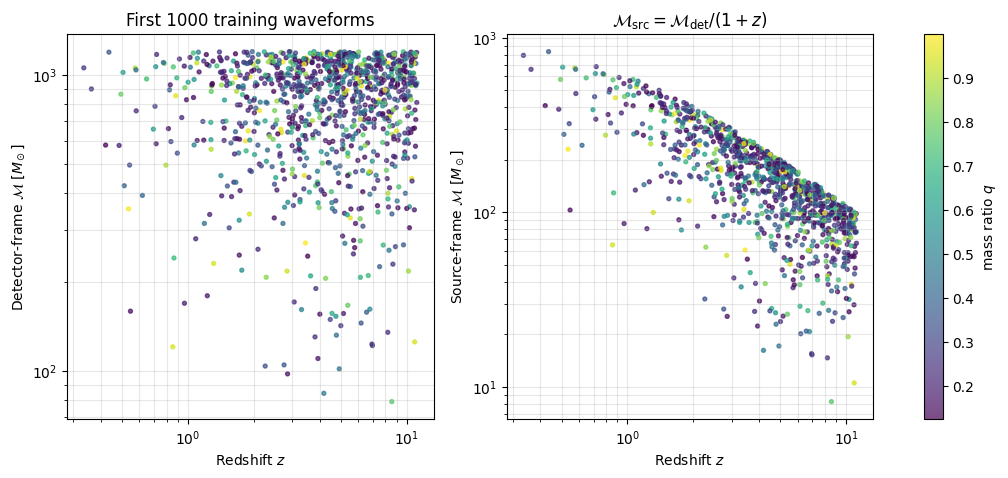

In [8]:
color = params["mass_ratio"].to_numpy() if "mass_ratio" in params else None
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)

for ax, mc, label in [(axes[0], mc_det, r"Detector-frame $\mathcal{M}$ [$M_\odot$]"),
                      (axes[1], mc_src, r"Source-frame $\mathcal{M}$ [$M_\odot$]")]:
    sc = ax.scatter(z[~bad], mc[~bad], c=None if color is None else color[~bad],
                    s=8, alpha=0.7, cmap="viridis")
    if bad.any():
        ax.scatter(z[bad], mc[bad], marker="x", c="red", s=30, label="NaN/inf waveform")
        ax.legend()
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Redshift $z$")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3, which="both")

if color is not None:
    fig.colorbar(sc, ax=axes, label="mass ratio $q$")
axes[0].set_title(f"First {n} training waveforms")
axes[1].set_title(r"$\mathcal{M}_\mathrm{src} = \mathcal{M}_\mathrm{det}/(1+z)$")
plt.show()

**Interpretation:** the redshifts are drawn independently of the waveforms, just as DINGO pairs
them at train time. The detector-frame panel therefore shows no correlation by construction.
The source-frame panel shows which physical masses the network effectively trains on.
At high $z$, even very heavy detector-frame systems correspond to light source-frame binaries.